# 💓 Heart Disease Prediction Using Machine Learning (UCI Cleveland)


In [ ]:











# 0) Environment & reproducibility
!pip -q install xgboost shap reportlab

import os, sys, warnings, datetime
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None

try:
    import shap
except Exception:
    shap = None

from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas
from reportlab.lib.units import inch

# Global config
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
warnings.filterwarnings("ignore")

OUTPUT_DIR = Path("/content")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = OUTPUT_DIR / "heart.csv"

def log(msg: str):
    print(f"[INFO] {msg}")

def print_versions() -> None:
    import sklearn
    print("== Library Versions ==")
    print("Python:", sys.version.split()[0])
    print("pandas:", pd.__version__)
    print("numpy:", np.__version__)
    print("scikit-learn:", sklearn.__version__)
    try:
        import xgboost
        print("xgboost:", xgboost.__version__)
    except Exception:
        print("xgboost: not installed")
    try:
        import shap as _shap
        print("shap:", _shap.__version__)
    except Exception:
        print("shap: not installed")
    print("matplotlib:", matplotlib.__version__)
    print("seaborn:", sns.__version__)

def save_df(df: pd.DataFrame, path: Path):
    df.to_csv(path, index=False)

print_versions()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 18.0 MB/s eta 0:00:00
== Library Versions ==
Python: 3.12.12
pandas: 2.2.2
numpy: 2.0.2
scikit-learn: 1.6.1
xgboost: 3.1.1
shap: 0.49.1
matplotlib: 3.10.0
seaborn: 0.13.2


In [ ]:
# 1) Project Overview & Objectives → saved as markdown files
overview = f"""# Project Overview
**Why it matters:** Cardiovascular disease is a leading global cause of death. Early prediction using routine clinical features can support triage and preventive care.

**Dataset:** UCI Cleveland subset (14 commonly used attributes + binary target).

**Applications:** Telemedicine triage, diagnostic decision support, population risk screening, and insurance analytics.

**Research Questions:**
1. Which features most influence heart-disease risk?
2. Which model (LR, RF, SVM, XGBoost) performs best?
3. Are results robust under cross-validation?
4. Can a simple UI power bedside prediction?

**Expected Outcome:** A reproducible ML pipeline with evaluation, feature importance, explainability, and a saved deployable model.
"""
(OUTPUT_DIR / "01_project_overview.md").write_text(overview)

objectives = """# Objectives
1. Identify key risk factors from patient attributes.
2. Train Logistic Regression, Random Forest, SVM (RBF), and XGBoost.
3. Compare Accuracy, Precision, Recall, F1, and ROC-AUC.
4. Visualize feature importance (age, cholesterol, BP, etc.).
5. (Optional) Provide a Streamlit mini UI for live predictions.
"""
(OUTPUT_DIR / "02_objectives.md").write_text(objectives)
log("✅ Wrote overview & objectives")


[INFO] ✅ Wrote overview & objectives


In [ ]:
# 2) Data acquisition + QA
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
GITHUB_URL = "https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv"
COLUMNS = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','target']

def load_dataset() -> pd.DataFrame:
    if DATA_FILE.exists():
        log(f"Loading local dataset from {DATA_FILE}")
        df = pd.read_csv(DATA_FILE)
        if list(df.columns) != COLUMNS:
            df.columns = COLUMNS[:len(df.columns)]
        return df
    # Try UCI first
    try:
        log("Downloading dataset from UCI…")
        df = pd.read_csv(UCI_URL, header=None, names=COLUMNS)
        df.replace("?", np.nan, inplace=True)
        for col in ["age","trestbps","chol","thalach","oldpeak","ca","thal"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        df.to_csv(DATA_FILE, index=False)
        return df
    except Exception:
        log("Fallback: downloading dataset from GitHub…")
        df = pd.read_csv(GITHUB_URL)
        df.columns = COLUMNS
        df.to_csv(DATA_FILE, index=False)
        return df

def profile_dataset(df: pd.DataFrame) -> None:
    save_df(df.head(10), OUTPUT_DIR/"out_head.csv")
    missing = df.isna().sum().reset_index(); missing.columns=["column","missing"]
    save_df(missing, OUTPUT_DIR/"out_missing.csv")
    uniq = df.nunique().reset_index(); uniq.columns=["column","unique_count"]
    save_df(uniq, OUTPUT_DIR/"out_unique_counts.csv")
    desc = df.describe(include="all").transpose().reset_index().rename(columns={"index":"column"})
    save_df(desc, OUTPUT_DIR/"out_describe.csv")

df = load_dataset()
log("✅ Loaded dataset")
print(df.info())
print("Shape:", df.shape)
print(df.isna().sum())

profile_dataset(df)
log("✅ Saved QA CSVs (head/missing/unique/describe)")


[INFO] Downloading dataset from UCI…
[INFO] ✅ Loaded dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
None
Shape: (303, 14)
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak   

In [ ]:
# 3) Preprocessing (ColumnTransformer + Pipelines) and splits
def build_preprocessor() -> ColumnTransformer:
    numeric = ['age','trestbps','chol','thalach','oldpeak','ca']
    categorical = ['cp','restecg','slope','thal']
    binary = ['sex','fbs','exang']
    pre = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="mean")), ("scaler", StandardScaler())]), numeric),
        ("cat", Pipeline([("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), categorical),
        ("bin", "passthrough", binary)
    ])
    return pre

def preprocess_data(df: pd.DataFrame):
    dup = df.duplicated().sum()
    if dup:
        log(f"Dropping {dup} duplicate rows…")
        df = df.drop_duplicates()
    if df["target"].max() > 1:
        log("Binarizing target (presence>0 → 1)…")
        df["target"] = (df["target"] > 0).astype(int)

    X = df.drop(columns=["target"])
    y = df["target"].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    pre = build_preprocessor()
    X_train_t = pre.fit_transform(X_train)
    X_test_t  = pre.transform(X_test)

    save_df(pd.DataFrame(X_train_t), OUTPUT_DIR/"processed_X_train.csv")
    save_df(pd.DataFrame(X_test_t),  OUTPUT_DIR/"processed_X_test.csv")
    save_df(pd.DataFrame(y_train, columns=["target"]), OUTPUT_DIR/"processed_y_train.csv")
    save_df(pd.DataFrame(y_test,  columns=["target"]), OUTPUT_DIR/"processed_y_test.csv")

    log(f"Train shape: {X_train_t.shape} | Test shape: {X_test_t.shape}")
    log("Train class balance:\n" + y_train.value_counts().to_string())
    return X, y, X_train, y_train, X_test, y_test, pre

X, y, X_train, y_train, X_test, y_test, pre = preprocess_data(df)


[INFO] Binarizing target (presence>0 → 1)…
[INFO] Train shape: (242, 19) | Test shape: (61, 19)
[INFO] Train class balance:
target
0    131
1    111


[INFO] 💾 Saved best pipeline: SVM → /content/best_heart_model.joblib
Sample inference → probability=0.142, class=0

== Best model: SVM
Among all evaluated models, SVM achieved the highest ROC-AUC on the validation set. These results should be clinically validated, calibrated, and audited for fairness before deployment.

== Inline preview of key figures ==


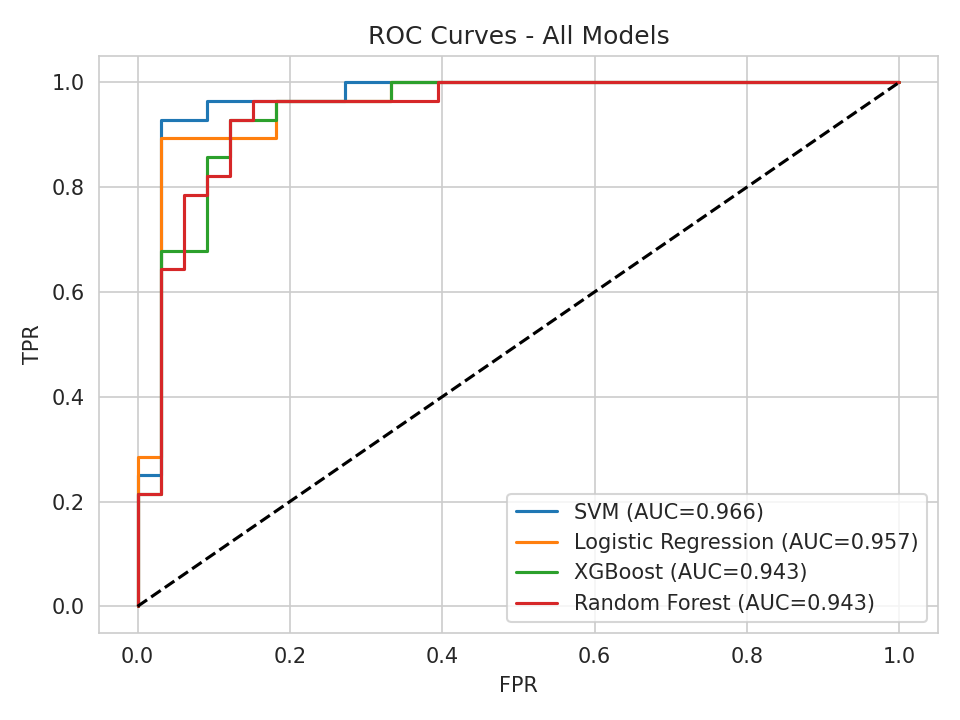

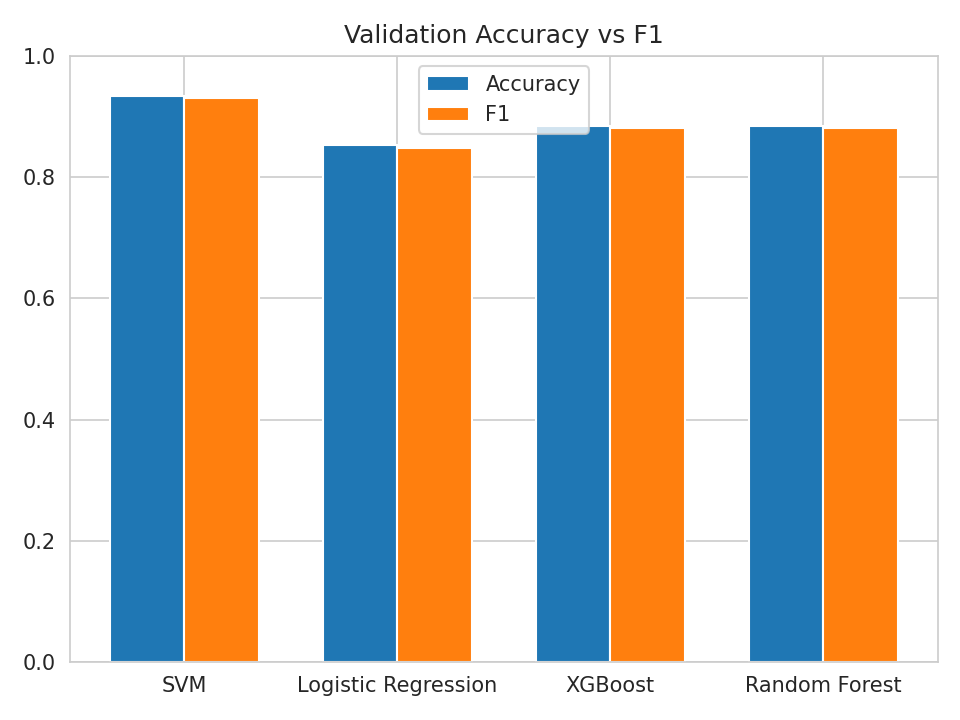

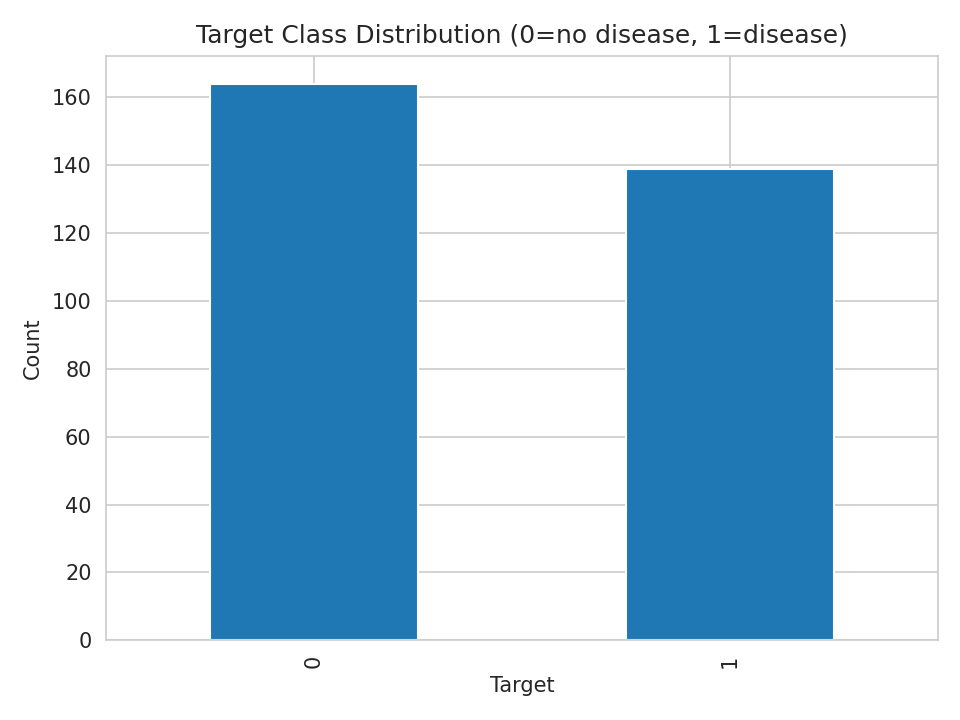

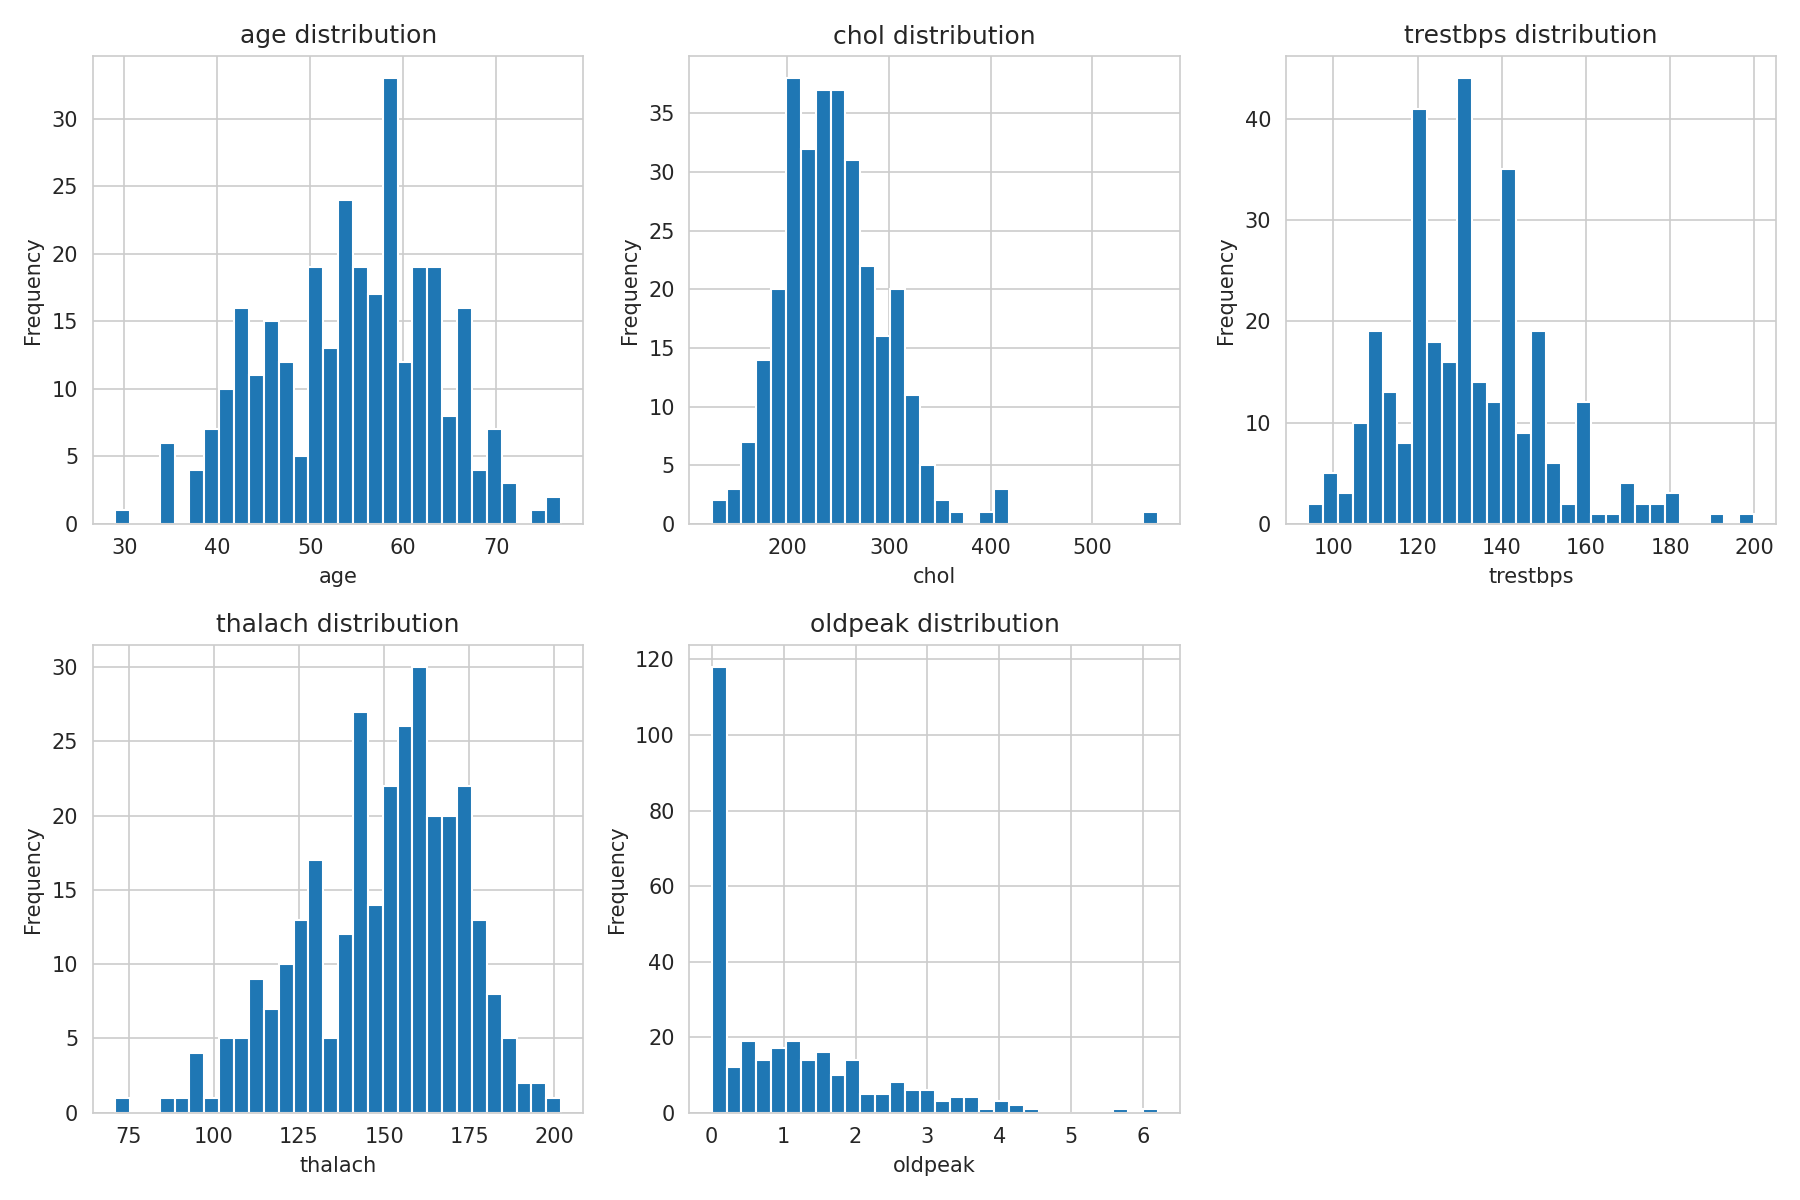

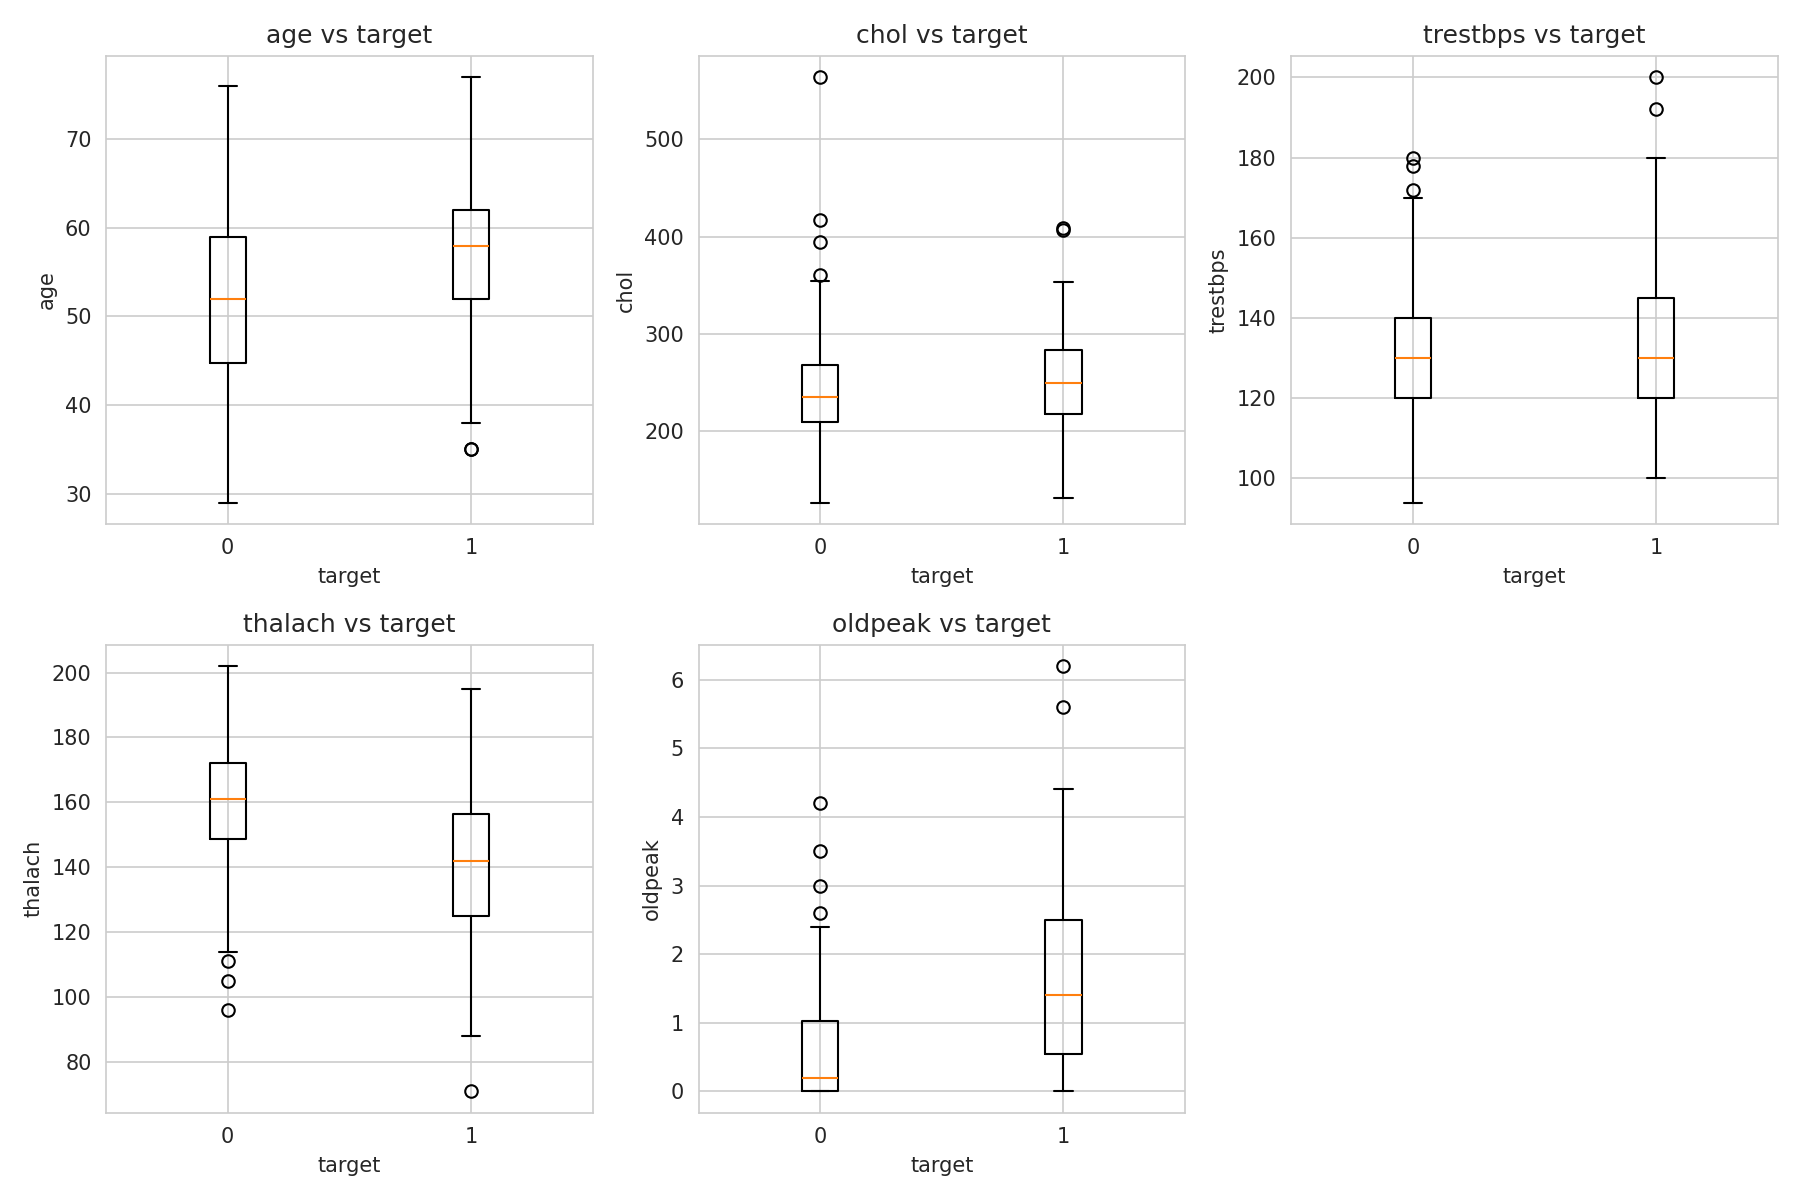

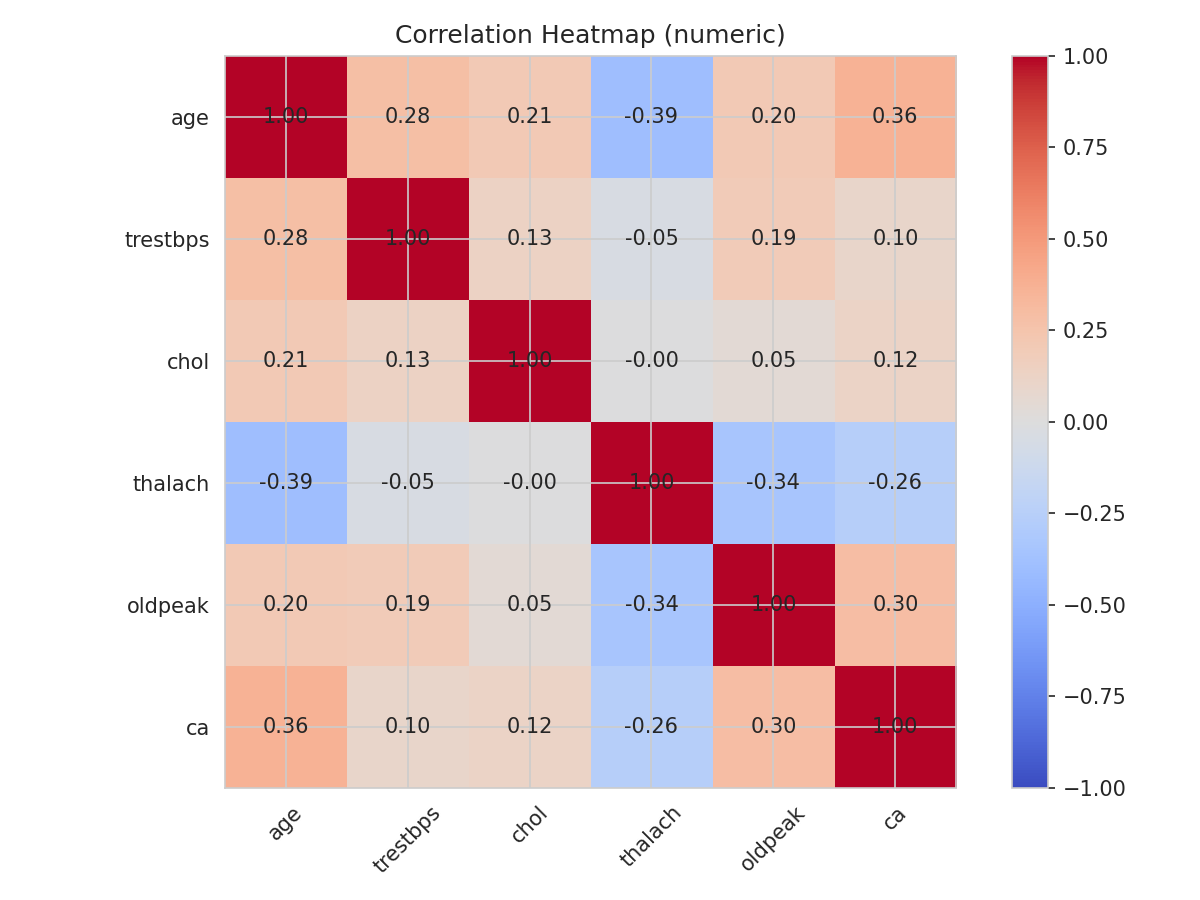

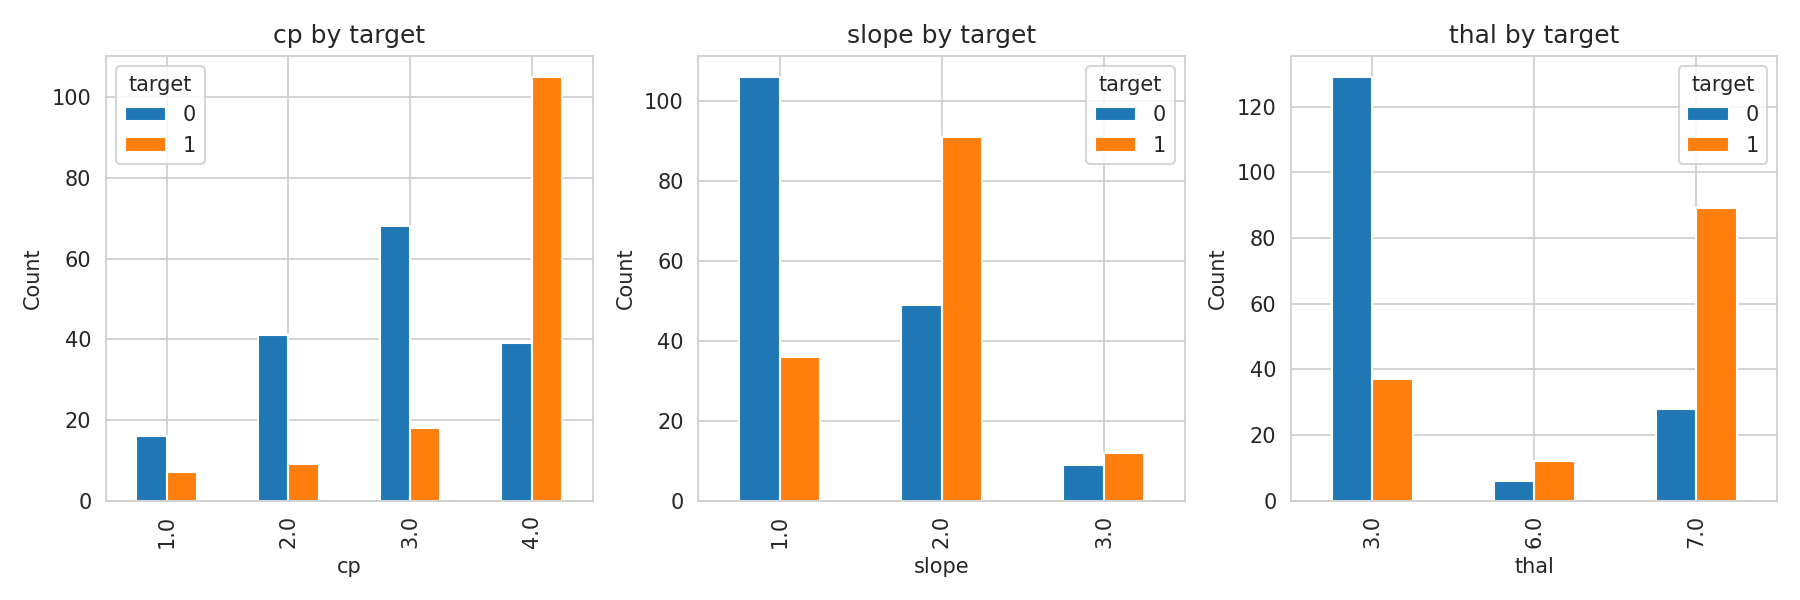

- fig_shap_summary.png not generated

== Generated files in /content ==
- .config
- 01_project_overview.md
- 02_objectives.md
- Heart_Disease_Prediction_Report.md
- Heart_Disease_Prediction_Report.pdf
- best_heart_model.joblib
- cv_summary.csv
- fig_boxplots_vs_target.png
- fig_class_balance.png
- fig_confusion_logistic_regression.png
- fig_confusion_logistic_regression_norm.png
- fig_confusion_random_forest.png
- fig_confusion_random_forest_norm.png
- fig_confusion_svm.png
- fig_confusion_svm_norm.png
- fig_confusion_xgboost.png
- fig_confusion_xgboost_norm.png
- fig_confusion_xgboost_tuned.png
- fig_confusion_xgboost_tuned_norm.png
- fig_corr_heatmap.png
- fig_countplots_cat.png
- fig_histograms.png
- fig_importance_logistic_regression.png
- fig_importance_random_forest.png
- fig_importance_xgboost.png
- fig_importance_xgboost_tuned.png
- fig_model_accuracy_f1.png
- fig_model_roc_all.png
- fig_roc_logistic_regression.png
- fig_roc_random_forest.png
- fig_roc_svm.png
- fig_roc_xgboost

In [ ]:
# 7) Feature importance, SHAP (optional), save best pipeline, inference, and reports
def feature_names(pre: ColumnTransformer) -> List[str]:
    num = ["age","trestbps","chol","thalach","oldpeak","ca"]
    cat = ["cp","restecg","slope","thal"]
    binf = ["sex","fbs","exang"]
    ohe = pre.named_transformers_["cat"].named_steps["onehot"]
    ohe_names = list(ohe.get_feature_names_out(cat))
    return num + ohe_names + binf

def plot_importance(name: str, pipe: Pipeline, feat_names: List[str], topn:int=10):
    clf = pipe.named_steps["clf"]; safe = name.lower().replace(" ","_")
    if hasattr(clf, "feature_importances_"):
        imp = clf.feature_importances_; idx = np.argsort(imp)[::-1][:topn]
        plt.figure(figsize=(8,5)); plt.barh(range(len(idx)), imp[idx][::-1])
        plt.yticks(range(len(idx)), [feat_names[i] for i in idx][::-1])
        plt.xlabel("Importance"); plt.title(f"Top {topn} Importances - {name}"); plt.tight_layout()
        plt.savefig(OUTPUT_DIR/f"fig_importance_{safe}.png", dpi=150); plt.close()
    elif hasattr(clf, "coef_"):
        coefs = np.abs(clf.coef_[0]); idx = np.argsort(coefs)[::-1][:topn]
        plt.figure(figsize=(8,5)); plt.barh(range(len(idx)), coefs[idx][::-1])
        plt.yticks(range(len(idx)), [feat_names[i] for i in idx][::-1])
        plt.xlabel("|Coefficient|"); plt.title(f"Top {topn} Coefficients - {name}"); plt.tight_layout()
        plt.savefig(OUTPUT_DIR/f"fig_importance_{safe}.png", dpi=150); plt.close()

def shap_summary_if_applicable(name: str, pipe: Pipeline, X_sample, feat_names: List[str]):
    if shap is None:
        log("SHAP not available; skipping")
        return
    clf = pipe.named_steps["clf"]
    if not (hasattr(clf,"get_booster") or hasattr(clf,"feature_importances_")):
        log("SHAP for tree models only; skipping")
        return
    try:
        expl = shap.TreeExplainer(clf)
        vals = expl.shap_values(X_sample)
        arr = vals if isinstance(vals, np.ndarray) else vals[0]
        plt.figure(); shap.summary_plot(arr, X_sample, feature_names=feat_names, plot_type="bar", show=False)
        plt.tight_layout(); plt.savefig(OUTPUT_DIR/"fig_shap_summary.png", dpi=150); plt.close(); log("SHAP summary saved")
    except Exception as e:
        log(f"SHAP error: {e}")

# Choose best model by ROC-AUC, then F1, then Accuracy
best_model = metrics_df.sort_values(["roc_auc","f1","acc_val"], ascending=False).iloc[0]["model"]
fnames = feature_names(pre)
for n in metrics_df["model"]:
    plot_importance(n, models[n], fnames)

if "XGBoost" in best_model or "Random Forest" in best_model:
    try:
        Xt_small = models[best_model].named_steps["preprocess"].transform(X_test)[:200]
        shap_summary_if_applicable(best_model, models[best_model], Xt_small, fnames)
    except Exception as e:
        log(f"SHAP skipped: {e}")

# Save best pipeline
import joblib
joblib.dump(models[best_model], OUTPUT_DIR/"best_heart_model.joblib")
log(f"💾 Saved best pipeline: {best_model} → /content/best_heart_model.joblib")

# Inference demo
def inference_demo(pipe: Pipeline):
    sample = {"age":45,"sex":1,"cp":2,"trestbps":130,"chol":230,"fbs":0,"restecg":1,"thalach":170,"exang":0,"oldpeak":1.2,"slope":2,"ca":0,"thal":2}
    df_ = pd.DataFrame([sample])
    if hasattr(pipe.named_steps["clf"],"predict_proba"):
        prob = pipe.predict_proba(df_)[0,1]
    elif hasattr(pipe.named_steps["clf"],"decision_function"):
        s = pipe.decision_function(df_); prob = (s - s.min())/(s.max()-s.min()+1e-8)
    else:
        prob = 0.0
    pred = int(prob >= 0.5)
    print(f"Sample inference → probability={prob:.3f}, class={pred}")

inference_demo(models[best_model])

# Markdown report + quick PDF
def write_report(best_model: str, metrics_df: pd.DataFrame, cv_df: pd.DataFrame):
    md = []
    md.append("# Heart Disease Prediction Using Machine Learning")
    md.append(f"**Date:** {datetime.date.today().isoformat()}")
    md.append("\n## Abstract")
    md.append("This project builds binary classifiers on the UCI Cleveland dataset. Pipelines include preprocessing, training (LR/RF/SVM/XGBoost), CV, tuning, and explainability. The best model is exported for deployment.")
    md.append("\n## Results")
    md.append(metrics_df.to_markdown(index=False))
    md.append("\n### Cross-Validation")
    md.append(cv_df.to_markdown(index=False))
    md.append(f"\n**Best model:** {best_model}")
    (OUTPUT_DIR/"Heart_Disease_Prediction_Report.md").write_text("\n".join(md))
    # Quick PDF via reportlab
    text = (OUTPUT_DIR/"Heart_Disease_Prediction_Report.md").read_text().split("\n")
    c = canvas.Canvas(str(OUTPUT_DIR/"Heart_Disease_Prediction_Report.pdf"), pagesize=letter)
    w,h = letter; x=0.5*inch; y=h-1*inch
    for line in text:
        if y <= 0.75*inch:
            c.showPage(); y=h-1*inch
        while len(line) > 100:
            c.drawString(x,y,line[:100]); y-=14; line=line[100:]
        c.drawString(x,y,line); y-=14
    c.save()

write_report(best_model, metrics_df, cv_df)
print("\n== Best model:", best_model)

# Final summary
summary = (f"Among all evaluated models, {best_model} achieved the highest ROC-AUC on the validation set. "
           "These results should be clinically validated, calibrated, and audited for fairness before deployment.")
(OUTPUT_DIR/"final_summary.txt").write_text(summary)
print(summary)

# Show key saved images inline (if present)
from IPython.display import Image, display
to_show = [
    "fig_model_roc_all.png",
    "fig_model_accuracy_f1.png",
    "fig_class_balance.png",
    "fig_histograms.png",
    "fig_boxplots_vs_target.png",
    "fig_corr_heatmap.png",
    "fig_countplots_cat.png",
    "fig_shap_summary.png",
]
print("\n== Inline preview of key figures ==")
for f in to_show:
    p = OUTPUT_DIR / f
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print("-", f, "not generated")

print("\n== Generated files in /content ==")
for f in sorted(os.listdir("/content")):
    print("-", f)


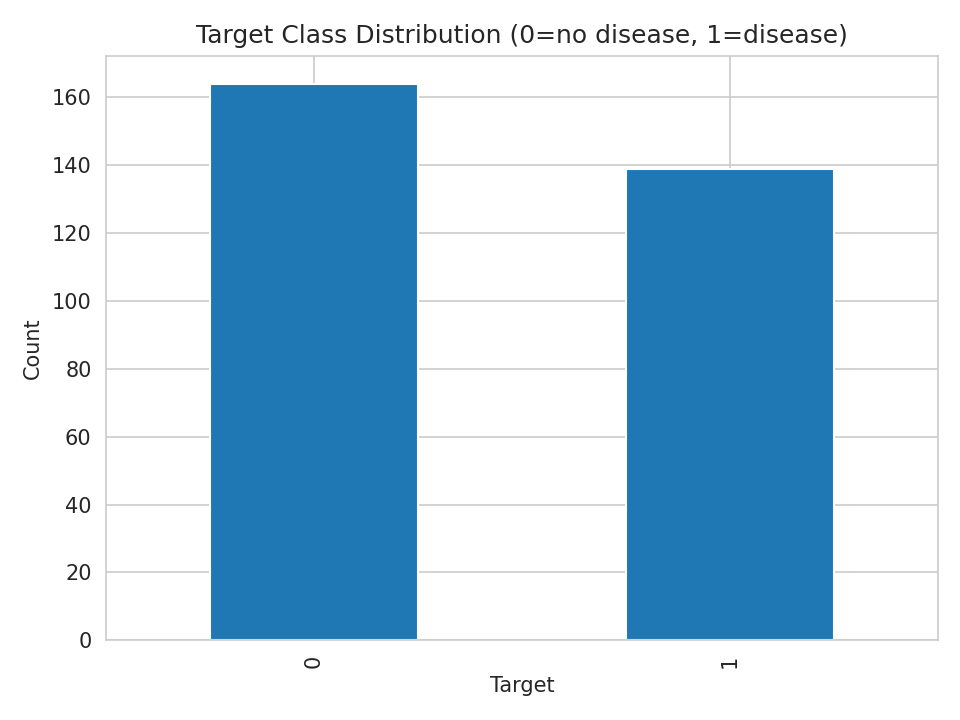

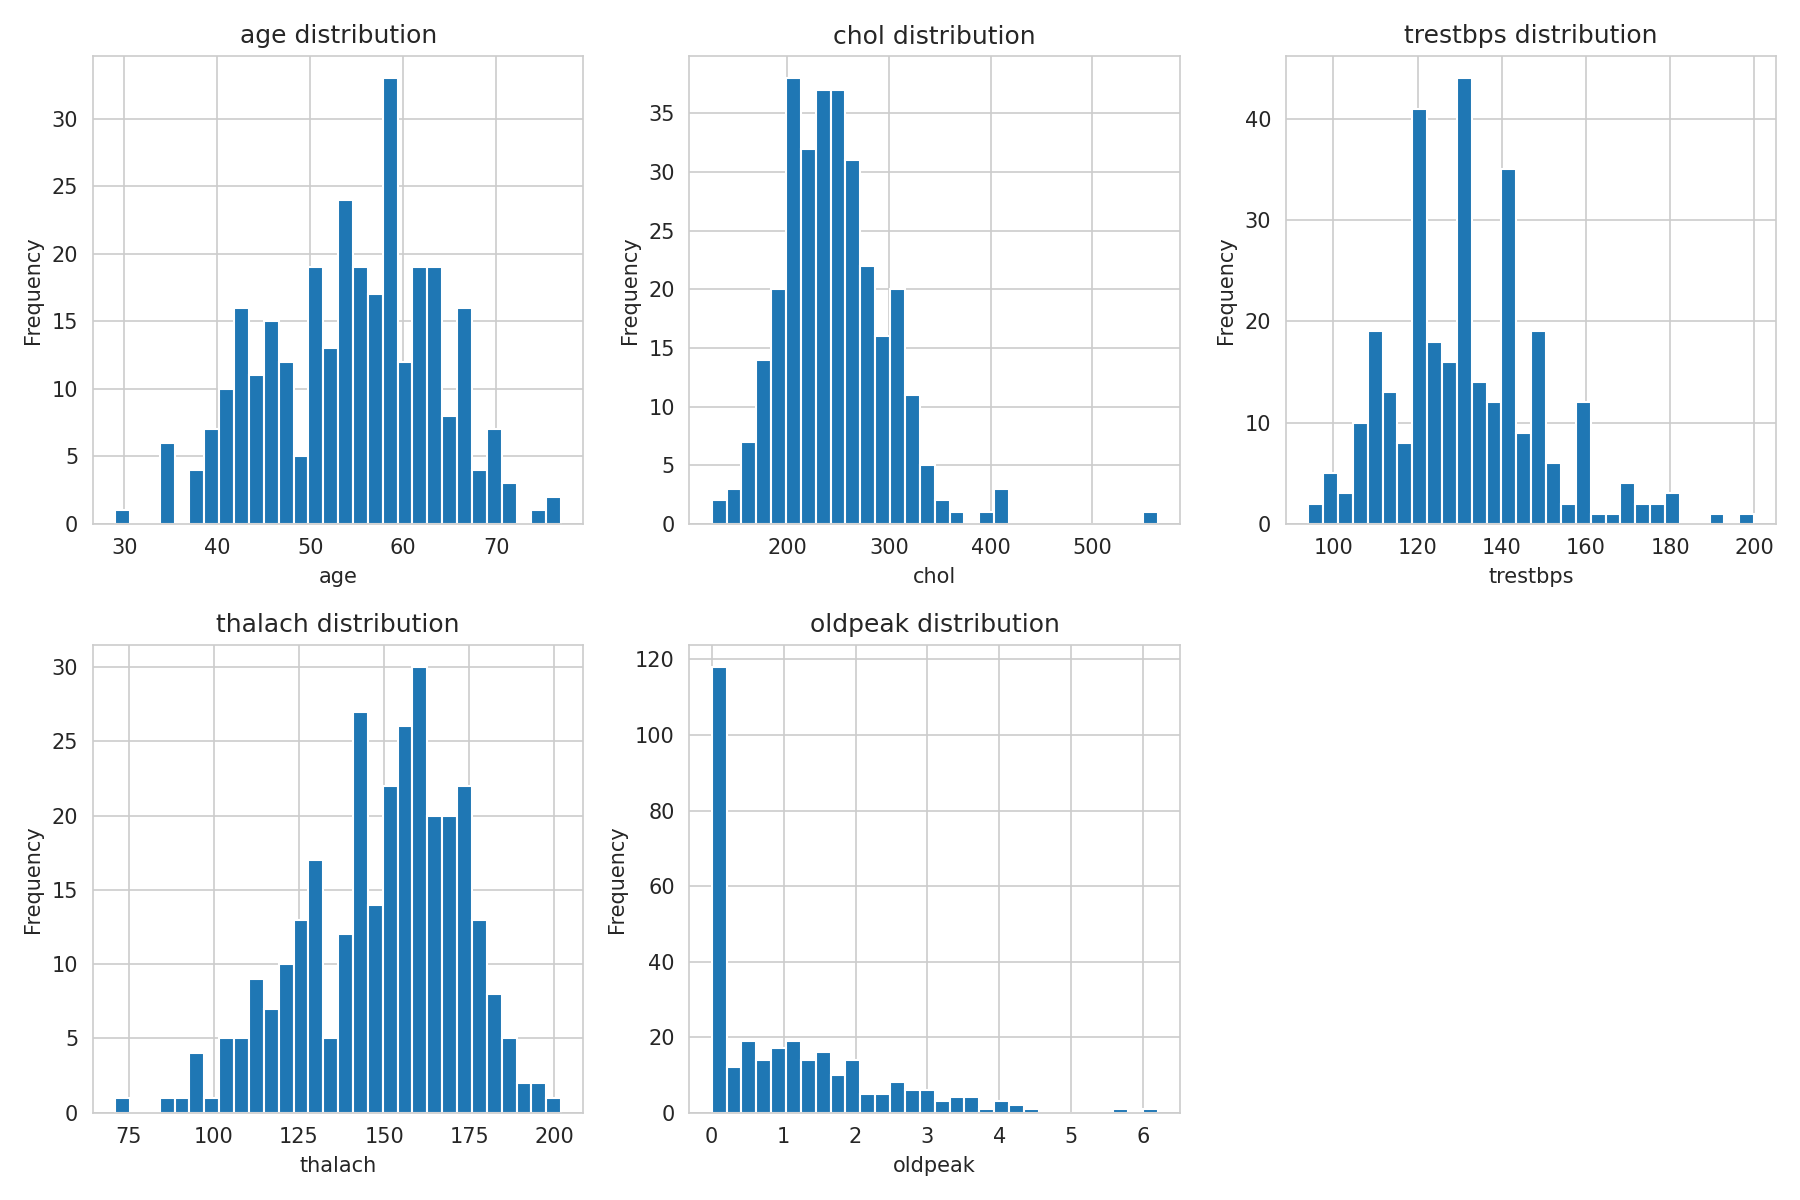

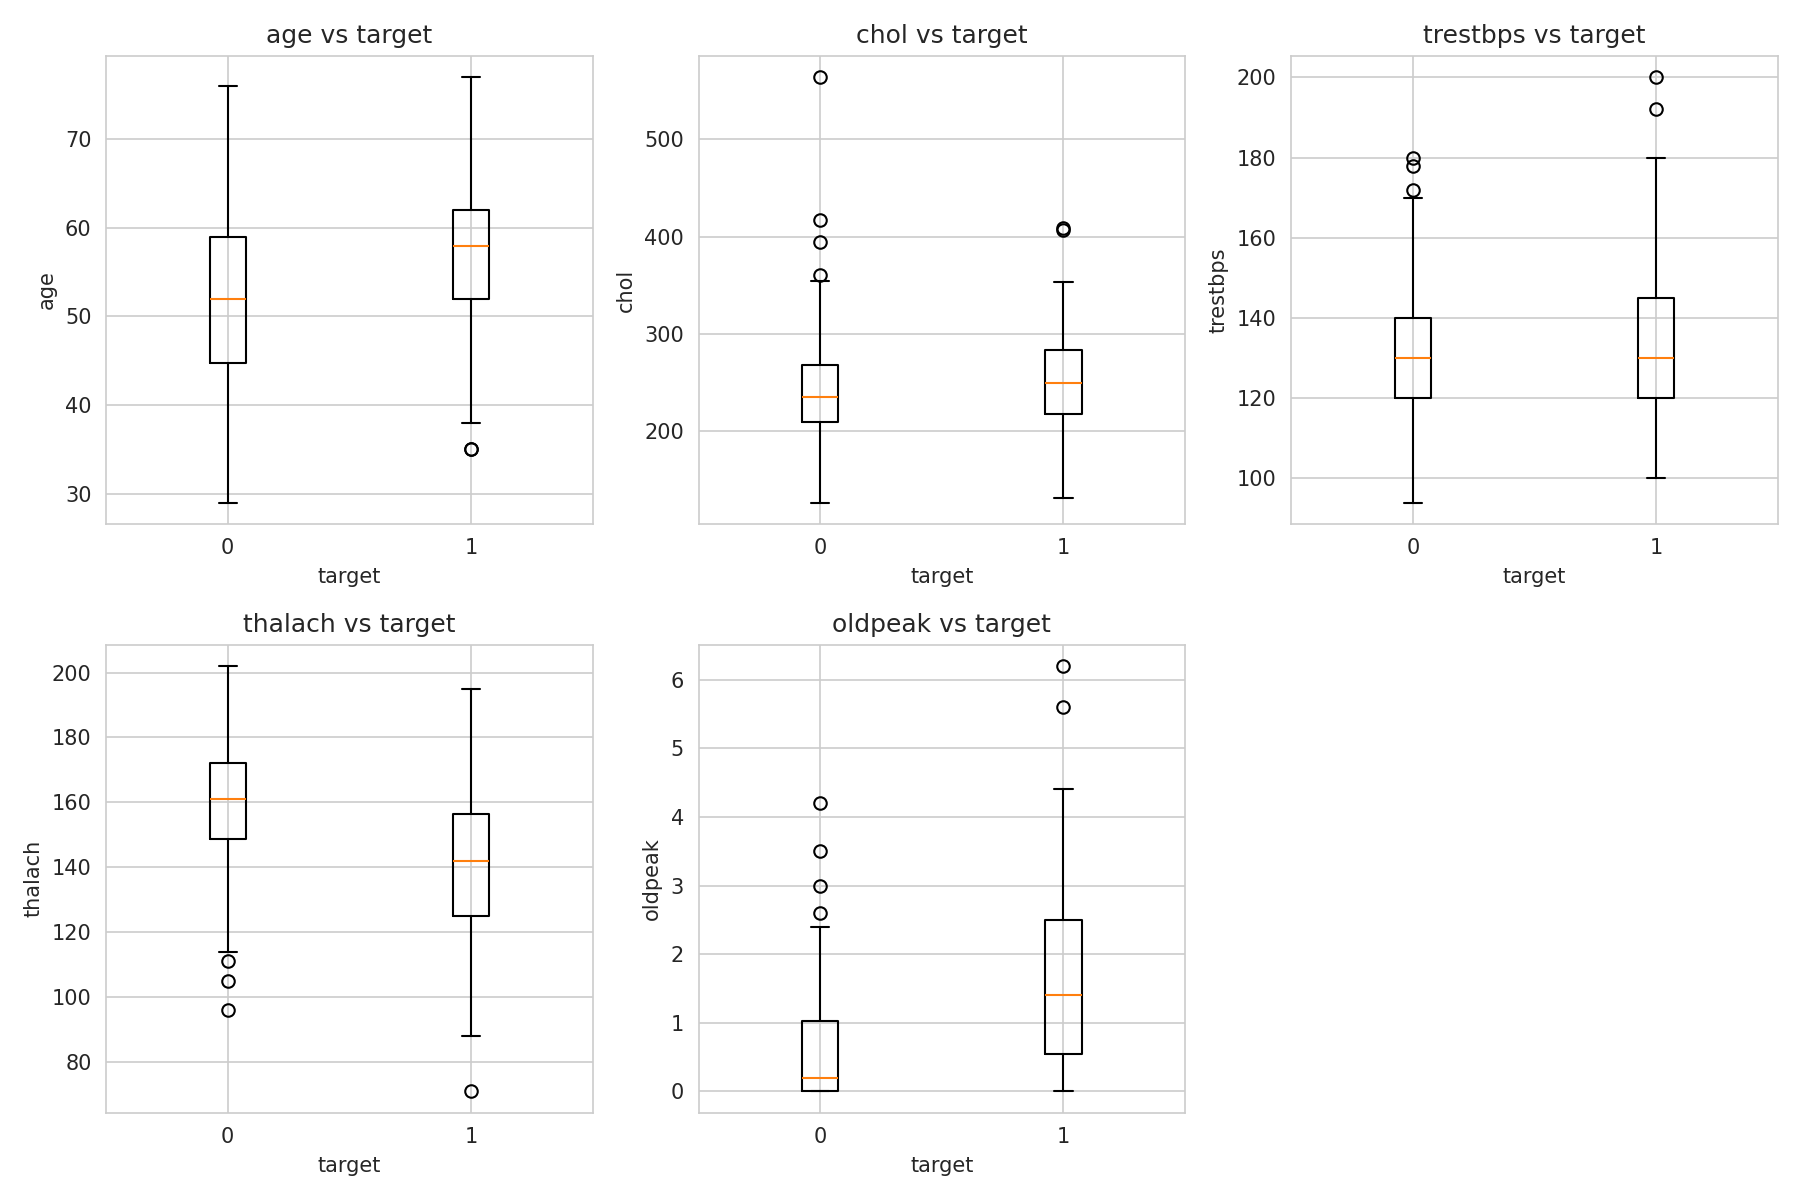

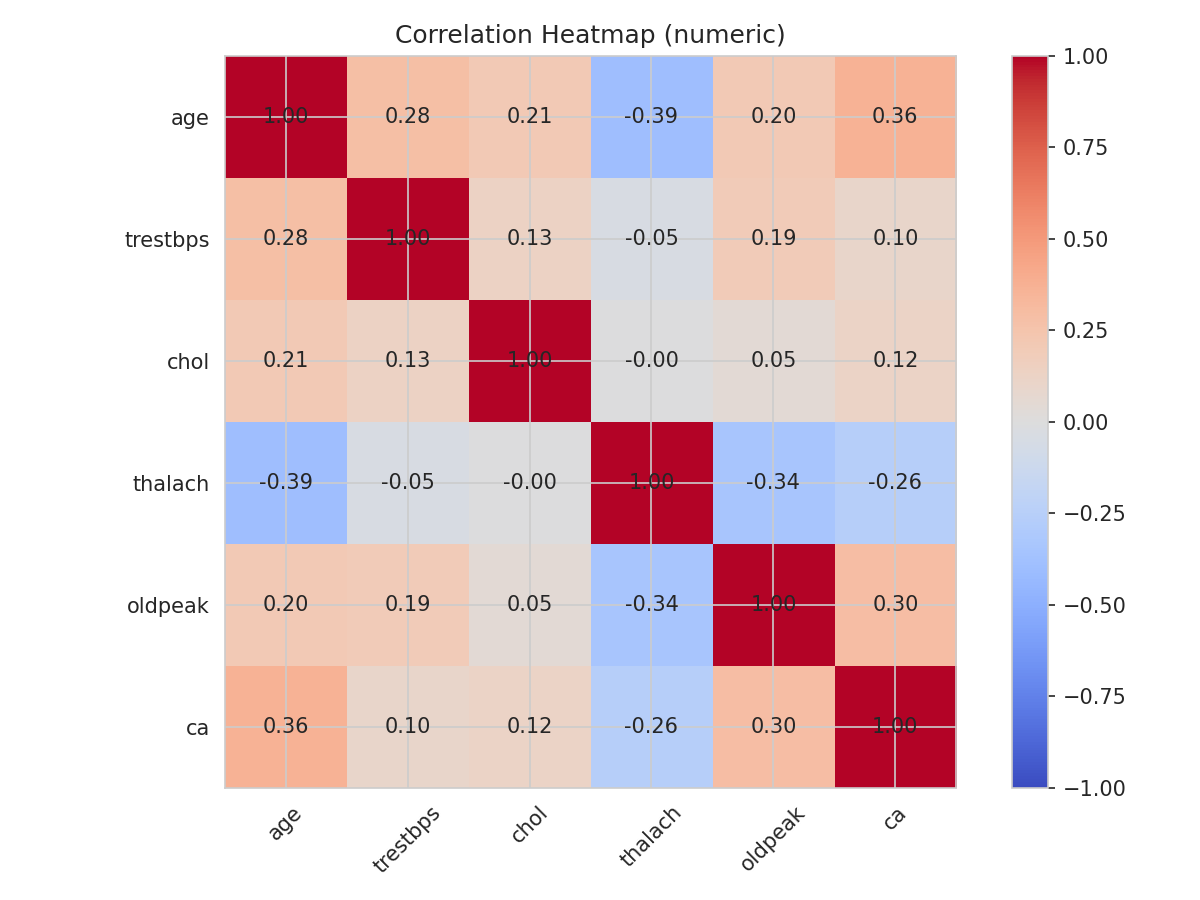

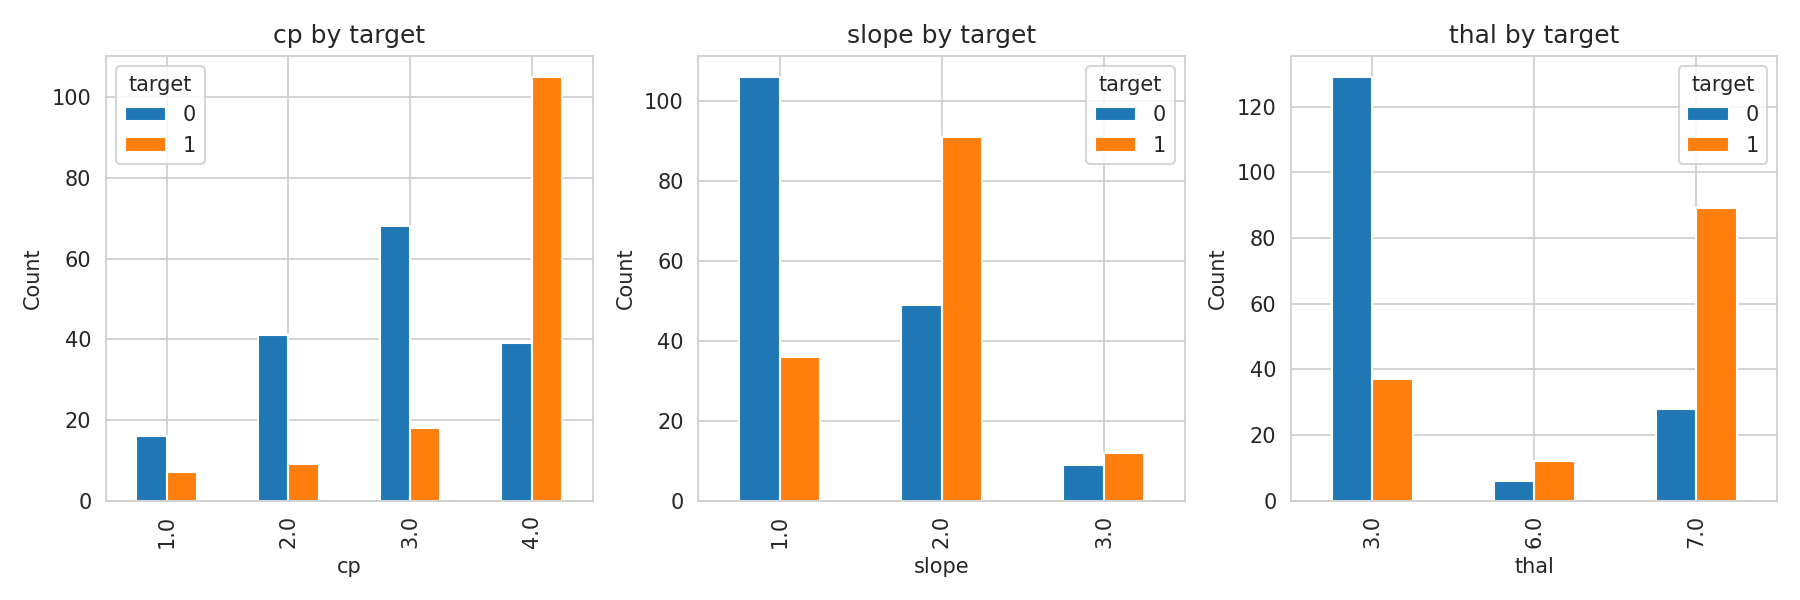

In [ ]:
# 4) EDA Plots (save + display)
from IPython.display import display, Image

def plot_class_balance(y: pd.Series):
    plt.figure()
    y.value_counts().sort_index().plot(kind="bar")
    plt.title("Target Class Distribution (0=no disease, 1=disease)")
    plt.xlabel("Target"); plt.ylabel("Count"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"fig_class_balance.png", dpi=150); plt.close()

def plot_histograms(df: pd.DataFrame):
    fig, axes = plt.subplots(2,3, figsize=(12,8)); axes = axes.flatten()
    cols=["age","chol","trestbps","thalach","oldpeak"]
    for i, col in enumerate(cols):
        axes[i].hist(df[col].dropna(), bins=30)
        axes[i].set_title(f"{col} distribution"); axes[i].set_xlabel(col); axes[i].set_ylabel("Frequency")
    axes[-1].axis("off"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"fig_histograms.png", dpi=150); plt.close()

def plot_boxplots(df: pd.DataFrame):
    fig, axes = plt.subplots(2,3, figsize=(12,8)); axes = axes.flatten()
    cols=["age","chol","trestbps","thalach","oldpeak"]
    for i, col in enumerate(cols):
        axes[i].boxplot([df[df["target"]==0][col].dropna(), df[df["target"]==1][col].dropna()], labels=["0","1"])
        axes[i].set_title(f"{col} vs target"); axes[i].set_xlabel("target"); axes[i].set_ylabel(col)
    axes[-1].axis("off"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"fig_boxplots_vs_target.png", dpi=150); plt.close()

def plot_corr_heatmap(df: pd.DataFrame):
    corr = df[["age","trestbps","chol","thalach","oldpeak","ca"]].corr()
    plt.figure(figsize=(8,6))
    im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(im); plt.xticks(range(len(corr.columns)), corr.columns, rotation=45); plt.yticks(range(len(corr.columns)), corr.columns)
    for i in range(len(corr)):
        for j in range(len(corr)):
            plt.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
    plt.title("Correlation Heatmap (numeric)"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"fig_corr_heatmap.png", dpi=150); plt.close()

def plot_countplots(df: pd.DataFrame):
    fig, axes = plt.subplots(1,3, figsize=(12,4))
    for ax, col in zip(axes, ["cp","slope","thal"]):
        ctab = pd.crosstab(df[col], df["target"])
        ctab.plot(kind="bar", ax=ax)
        ax.set_title(f"{col} by target"); ax.set_xlabel(col); ax.set_ylabel("Count")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/"fig_countplots_cat.png", dpi=150); plt.close()

plot_class_balance(df["target"]); display(Image(filename=str(OUTPUT_DIR/"fig_class_balance.png")))
plot_histograms(df);               display(Image(filename=str(OUTPUT_DIR/"fig_histograms.png")))
plot_boxplots(df);                 display(Image(filename=str(OUTPUT_DIR/"fig_boxplots_vs_target.png")))
plot_corr_heatmap(df);             display(Image(filename=str(OUTPUT_DIR/"fig_corr_heatmap.png")))
plot_countplots(df);               display(Image(filename=str(OUTPUT_DIR/"fig_countplots_cat.png")))


[INFO] 🔄 Training Logistic Regression…
[INFO] 🔎 Evaluating Logistic Regression…

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0      0.900     0.818     0.857        33
           1      0.806     0.893     0.847        28

    accuracy                          0.852        61
   macro avg      0.853     0.856     0.852        61
weighted avg      0.857     0.852     0.853        61

[INFO] ✅ Completed Logistic Regression
[INFO] 🔄 Training Random Forest…
[INFO] 🔎 Evaluating Random Forest…

Random Forest Classification Report:
              precision    recall  f1-score   support

           0      0.933     0.848     0.889        33
           1      0.839     0.929     0.881        28

    accuracy                          0.885        61
   macro avg      0.886     0.889     0.885        61
weighted avg      0.890     0.885     0.885        61

[INFO] ✅ Completed Random Forest
[INFO] 🔄 Training SVM…
[INFO] 🔎 Evaluating S

,model,acc_train,acc_val,precision,recall,f1,roc_auc
0,SVM,0.896694,0.934426,0.900000,0.964286,0.931034,0.966450
1,Logistic Regression,0.859504,0.852459,0.806452,0.892857,0.847458,0.956710
2,XGBoost,1.000000,0.885246,0.838710,0.928571,0.881356,0.942641
3,Random Forest,1.000000,0.885246,0.838710,0.928571,0.881356,0.942641


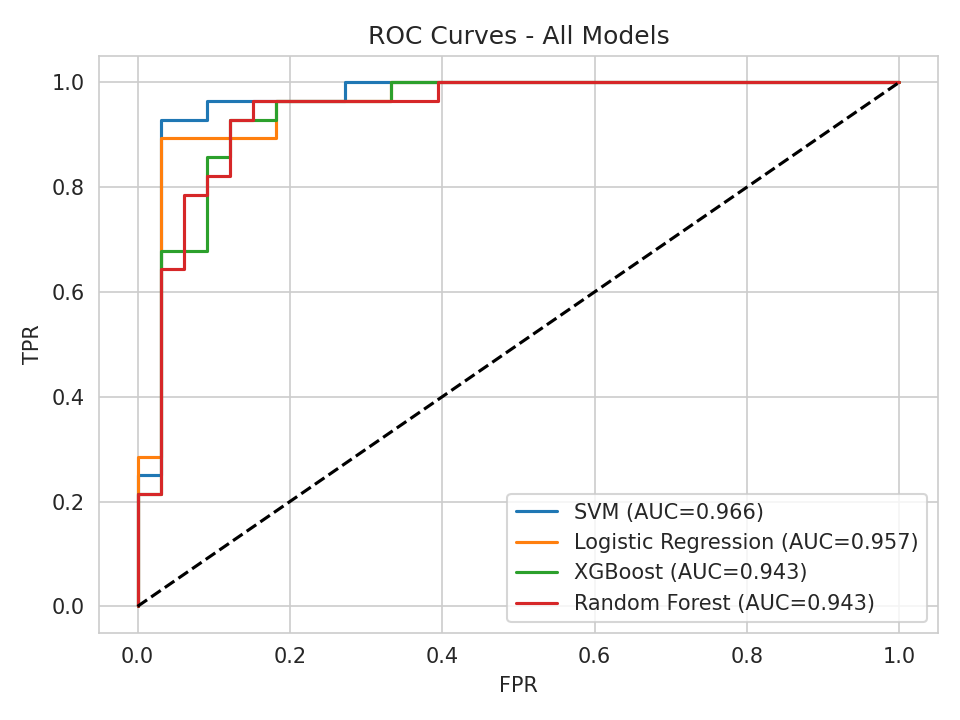

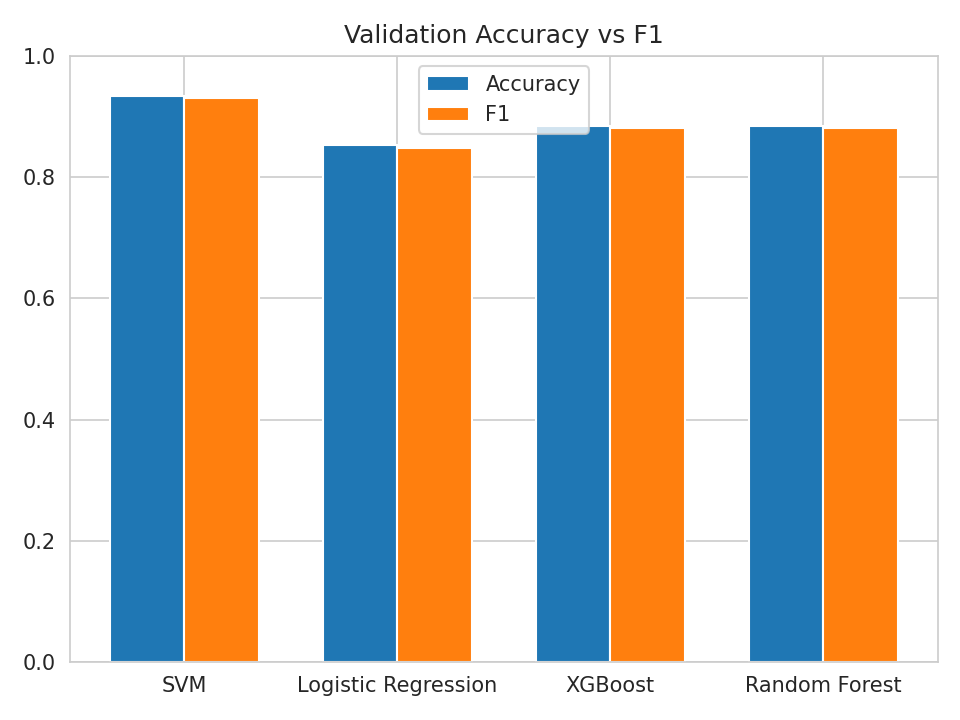

<Figure size 800x500 with 0 Axes>

In [ ]:
# 5) Modeling, evaluation, and aggregate plots
def build_clf_pipeline(pre: ColumnTransformer, est) -> Pipeline:
    return Pipeline([("preprocess", pre), ("clf", est)])

def evaluate_model(name: str, pipe: Pipeline, X_train, y_train, X_test, y_test) -> dict:
    log(f"🔄 Training {name}…")
    pipe.fit(X_train, y_train)
    log(f"🔎 Evaluating {name}…")
    y_pred_tr = pipe.predict(X_train)
    y_pred = pipe.predict(X_test)
    if hasattr(pipe.named_steps["clf"], "predict_proba"):
        y_proba = pipe.predict_proba(X_test)[:,1]
    elif hasattr(pipe.named_steps["clf"], "decision_function"):
        s = pipe.decision_function(X_test); y_proba = (s - s.min())/(s.max()-s.min()+1e-8)
    else:
        y_proba = np.zeros_like(y_pred, dtype=float)
    met = {
        "model": name,
        "acc_train": accuracy_score(y_train, y_pred_tr),
        "acc_val": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
    }
    print(f"\n{name} Classification Report:\n" + classification_report(y_test, y_pred, digits=3, zero_division=0))
    pd.DataFrame({"y_true":y_test,"y_pred":y_pred,"y_proba":y_proba}).to_csv(OUTPUT_DIR/f"predictions_{name.lower().replace(' ','_')}.csv", index=False)
    # Confusions
    cm = confusion_matrix(y_test, y_pred); cmn = confusion_matrix(y_test, y_pred, normalize="true")
    for mat, suf in [(cm,""),(cmn,"_norm")]:
        plt.figure(); plt.imshow(mat, cmap="Blues"); plt.colorbar()
        plt.xticks([0,1],["0","1"]); plt.yticks([0,1],["0","1"])
        for i in range(2):
            for j in range(2):
                val = mat[i,j] if suf=="" else f"{mat[i,j]:.2f}"
                plt.text(j,i,val,ha="center",va="center")
        plt.xlabel("Predicted"); plt.ylabel("True")
        plt.title(f"{name} Confusion Matrix" + (" (Norm)" if suf else "")); plt.tight_layout()
        plt.savefig(OUTPUT_DIR/f"fig_confusion_{name.lower().replace(' ','_')}{suf}.png", dpi=150); plt.close()
    # ROC
    fpr,tpr,_ = roc_curve(y_test, y_proba)
    plt.figure(); plt.plot(fpr,tpr,label=f"{name} (AUC={met['roc_auc']:.3f})"); plt.plot([0,1],[0,1],"k--")
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"ROC Curve - {name}"); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/f"fig_roc_{name.lower().replace(' ','_')}.png", dpi=150); plt.close()
    log(f"✅ Completed {name}")
    return met

def train_all(pre, X_train, y_train, X_test, y_test):
    results = []; models = {}
    defs = [
        ("Logistic Regression", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
        ("Random Forest",       RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)),
        ("SVM",                 SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
    ]
    if XGBClassifier is not None:
        defs.append(("XGBoost", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0, eval_metric="logloss", random_state=RANDOM_STATE)))
    for name, est in defs:
        pipe = build_clf_pipeline(pre, est)
        met = evaluate_model(name, pipe, X_train, y_train, X_test, y_test)
        results.append(met); models[name] = pipe
    met_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
    save_df(met_df, OUTPUT_DIR/"metrics_comparison.csv")
    # Overlay ROC
    plt.figure()
    for name in met_df["model"]:
        pipe = models[name]
        if hasattr(pipe.named_steps["clf"],"predict_proba"):
            proba = pipe.predict_proba(X_test)[:,1]
        elif hasattr(pipe.named_steps["clf"],"decision_function"):
            s = pipe.decision_function(X_test); proba = (s - s.min())/(s.max()-s.min()+1e-8)
        else:
            proba = np.zeros_like(y_test, dtype=float)
        fpr,tpr,_ = roc_curve(y_test, proba); auc = roc_auc_score(y_test, proba)
        plt.plot(fpr,tpr,label=f"{name} (AUC={auc:.3f})")
    plt.plot([0,1],[0,1],"k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC Curves - All Models"); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/"fig_model_roc_all.png", dpi=150); plt.close()
    # Acc vs F1
    plt.figure(figsize=(8,5))
    x = np.arange(len(met_df)); width=0.35
    fig,ax = plt.subplots()
    ax.bar(x-width/2, met_df["acc_val"], width, label="Accuracy")
    ax.bar(x+width/2, met_df["f1"], width, label="F1")
    ax.set_xticks(x); ax.set_xticklabels(met_df["model"]); ax.set_ylim(0,1); ax.legend(); ax.set_title("Validation Accuracy vs F1")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR/"fig_model_accuracy_f1.png", dpi=150); plt.close()
    return met_df, models

metrics_df, models = train_all(pre, X_train, y_train, X_test, y_test)
display(pd.read_csv(OUTPUT_DIR/"metrics_comparison.csv"))
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR/"fig_model_roc_all.png")))
display(Image(filename=str(OUTPUT_DIR/"fig_model_accuracy_f1.png")))


In [ ]:
# 6) Cross-validation + XGBoost GridSearchCV tuning
def cross_validate(pre, X, y):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    defs = [
        ("Logistic Regression", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
        ("Random Forest",       RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)),
        ("SVM",                 SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
    ]
    if XGBClassifier is not None:
        defs.append(("XGBoost", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0, eval_metric="logloss", random_state=RANDOM_STATE)))
    for name, est in defs:
        pipe = build_clf_pipeline(pre, est)
        scores = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
        rows.append({"model": name, "cv_auc_mean": scores.mean(), "cv_auc_std": scores.std()})
        log(f"CV {name}: AUC={scores.mean():.3f}±{scores.std():.3f}")
    cv_df = pd.DataFrame(rows)
    save_df(cv_df, OUTPUT_DIR/"cv_summary.csv")
    return cv_df

def tune_xgb(pre, X_train, y_train, X_test, y_test, met_df, models):
    if XGBClassifier is None:
        log("XGBoost unavailable; skipping tuning")
        return met_df, models
    grid = {
        "clf__n_estimators": [300, 500, 800],
        "clf__learning_rate": [0.03, 0.05, 0.1],
        "clf__max_depth": [3, 4, 5],
        "clf__subsample": [0.8, 1.0],
        "clf__colsample_bytree": [0.8, 1.0],
        "clf__reg_lambda": [1.0, 1.5, 2.0],
    }
    base = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, use_label_encoder=False)
    gs = GridSearchCV(build_clf_pipeline(pre, base), grid, scoring="roc_auc",
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
    log("Tuning XGBoost (GridSearchCV)…")
    gs.fit(X_train, y_train)
    log(f"Best params: {gs.best_params_}")
    tuned = gs.best_estimator_
    met = evaluate_model("XGBoost_tuned", tuned, X_train, y_train, X_test, y_test)
    met_df = pd.concat([met_df, pd.DataFrame([met])], ignore_index=True).sort_values("roc_auc", ascending=False)
    save_df(met_df, OUTPUT_DIR/"metrics_comparison.csv")
    models["XGBoost_tuned"] = tuned
    return met_df, models

cv_df = cross_validate(pre, X, y)
display(pd.read_csv(OUTPUT_DIR/"cv_summary.csv"))
metrics_df, models = tune_xgb(pre, X_train, y_train, X_test, y_test, metrics_df, models)
display(pd.read_csv(OUTPUT_DIR/"metrics_comparison.csv"))


[INFO] CV Logistic Regression: AUC=0.915±0.021
[INFO] CV Random Forest: AUC=0.911±0.022
[INFO] CV SVM: AUC=0.899±0.035
[INFO] CV XGBoost: AUC=0.891±0.019


,model,cv_auc_mean,cv_auc_std
0,Logistic Regression,0.914802,0.021209
1,Random Forest,0.911493,0.022156
2,SVM,0.899324,0.035423
3,XGBoost,0.890519,0.019457


[INFO] Tuning XGBoost (GridSearchCV)…
[INFO] Best params: {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.03, 'clf__max_depth': 4, 'clf__n_estimators': 300, 'clf__reg_lambda': 2.0, 'clf__subsample': 1.0}
[INFO] 🔄 Training XGBoost_tuned…
[INFO] 🔎 Evaluating XGBoost_tuned…

XGBoost_tuned Classification Report:
              precision    recall  f1-score   support

           0      0.935     0.879     0.906        33
           1      0.867     0.929     0.897        28

    accuracy                          0.902        61
   macro avg      0.901     0.904     0.901        61
weighted avg      0.904     0.902     0.902        61

[INFO] ✅ Completed XGBoost_tuned


,model,acc_train,acc_val,precision,recall,f1,roc_auc
0,SVM,0.896694,0.934426,0.900000,0.964286,0.931034,0.966450
1,Logistic Regression,0.859504,0.852459,0.806452,0.892857,0.847458,0.956710
2,XGBoost,1.000000,0.885246,0.838710,0.928571,0.881356,0.942641
3,Random Forest,1.000000,0.885246,0.838710,0.928571,0.881356,0.942641
4,XGBoost_tuned,0.991736,0.901639,0.866667,0.928571,0.896552,0.941558
